# R Programming — Practical No. 07
**Experiment:** Customer Segmentation and Predictive Analytics Using Machine Learning  
**Name:** Tanishq Kulkarni  
**Roll No.:** 24102A2007

**Problem:** Segment online retail customers using RFM, K-Means and hierarchical clustering; identify high-value customers and predict membership using Random Forest and SVM.  
**Dataset:** UCI Online Retail (transactions from 2010–2011). The online dataset will be downloaded when this notebook is executed in Colab.


In [ ]:
packages <- c("readxl", "dplyr", "lubridate", "ggplot2", "cluster", "randomForest", "e1071", "pROC", "plotly")
new_packages <- packages[!sapply(packages, requireNamespace, quietly = TRUE)]
if (length(new_packages)) install.packages(new_packages, repos = "https://cloud.r-project.org", quiet = TRUE)
invisible(lapply(packages, library, character.only = TRUE))
set.seed(42)

## 1. Load and inspect data

In [ ]:
url <- "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
zipfile <- tempfile(fileext = ".zip")
download.file(url, zipfile, mode = "wb")
folder <- tempfile()
dir.create(folder)
unzip(zipfile, exdir = folder)
filename <- list.files(folder, pattern = "\\.xlsx$", full.names = TRUE, recursive = TRUE)[1]
retail <- readxl::read_excel(filename)
print(dim(retail))
print(head(retail))
print(colSums(is.na(retail)))

[1] 541909      8
# A tibble: 6 × 8
  InvoiceNo StockCode Description         Quantity InvoiceDate         UnitPrice
  <chr>     <chr>     <chr>                  <dbl> <dttm>                  <dbl>
1 536365    85123A    WHITE HANGING HEAR…        6 2010-12-01 08:26:00      2.55
2 536365    71053     WHITE METAL LANTERN        6 2010-12-01 08:26:00      3.39
3 536365    84406B    CREAM CUPID HEARTS…        8 2010-12-01 08:26:00      2.75
4 536365    84029G    KNITTED UNION FLAG…        6 2010-12-01 08:26:00      3.39
5 536365    84029E    RED WOOLLY HOTTIE …        6 2010-12-01 08:26:00      3.39
6 536365    22752     SET 7 BABUSHKA NES…        2 2010-12-01 08:26:00      7.65
# ℹ 2 more variables: CustomerID <dbl>, Country <chr>
  InvoiceNo   StockCode Description    Quantity InvoiceDate   UnitPrice 
          0           0        1454           0           0           0 
 CustomerID     Country 
     135080           0 


## 2. Clean transactions and engineer customer features

In [ ]:
retail <- retail |>
  filter(!is.na(CustomerID), !is.na(InvoiceDate), Quantity > 0, UnitPrice > 0,
         !grepl("^C", as.character(InvoiceNo))) |>
  mutate(CustomerID = as.character(CustomerID),
         InvoiceNo = as.character(InvoiceNo),
         Sales = Quantity * UnitPrice,
         InvoiceDate = as.POSIXct(InvoiceDate, tz = "UTC"))
reference_date <- max(retail$InvoiceDate) + lubridate::days(1)
customers <- retail |>
  group_by(CustomerID) |>
  summarise(Recency = as.numeric(difftime(reference_date, max(InvoiceDate), units = "days")),
            Frequency = n_distinct(InvoiceNo), Monetary = sum(Sales),
            AvgTransaction = Monetary / Frequency,
            Quantity = sum(Quantity),
            PurchaseFrequency = Frequency / pmax(1, as.numeric(difftime(max(InvoiceDate), min(InvoiceDate), units = "days")) / 30 + 1),
            .groups = "drop")
features <- c("Recency", "Frequency", "Monetary", "AvgTransaction", "Quantity", "PurchaseFrequency")
customers[features] <- lapply(customers[features], function(x) pmin(x, quantile(x, .99, na.rm = TRUE)))
X <- scale(log1p(customers[features]))
print(summary(customers[features]))

    Recency         Frequency         Monetary        AvgTransaction   
 Min.   :  1.00   Min.   : 1.000   Min.   :    3.75   Min.   :   3.45  
 1st Qu.: 18.07   1st Qu.: 1.000   1st Qu.:  307.42   1st Qu.: 178.62  
 Median : 51.09   Median : 2.000   Median :  674.49   Median : 293.90  
 Mean   : 93.02   Mean   : 4.009   Mean   : 1598.58   Mean   : 365.58  
 3rd Qu.:142.73   3rd Qu.: 5.000   3rd Qu.: 1661.74   3rd Qu.: 430.11  
 Max.   :369.67   Max.   :30.000   Max.   :19881.00   Max.   :2031.16  
    Quantity       PurchaseFrequency
 Min.   :    1.0   Min.   :0.1515   
 1st Qu.:  160.0   1st Qu.:0.5278   
 Median :  379.0   Median :1.0000   
 Mean   :  925.9   Mean   :0.8755   
 3rd Qu.:  992.8   3rd Qu.:1.0000   
 Max.   :11046.6   Max.   :2.9620   


## 3. Elbow method and silhouette score

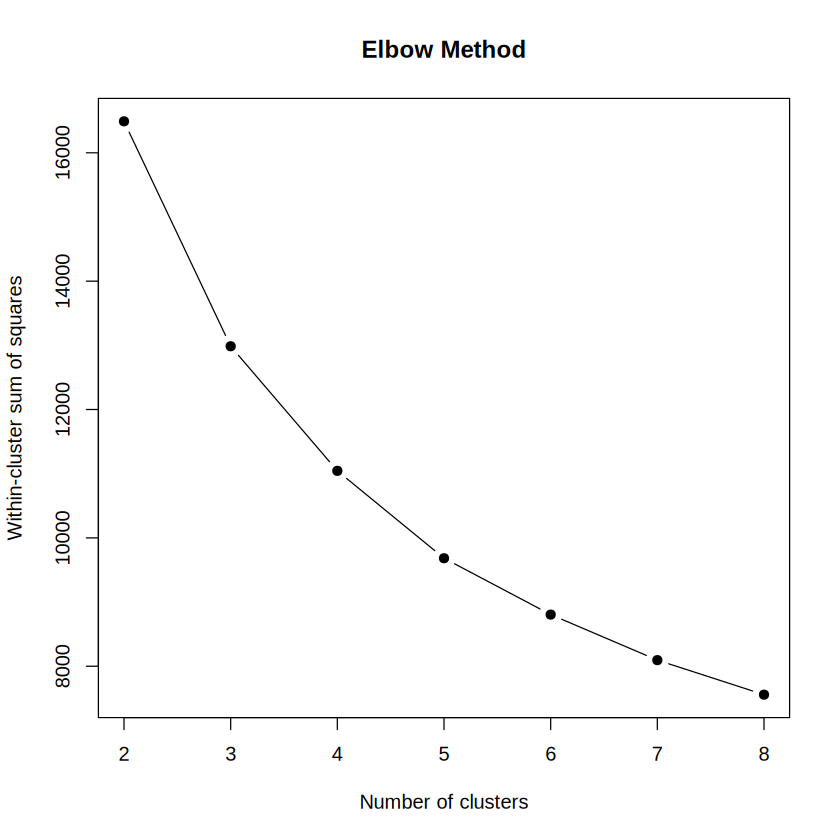

Selected k: 2 


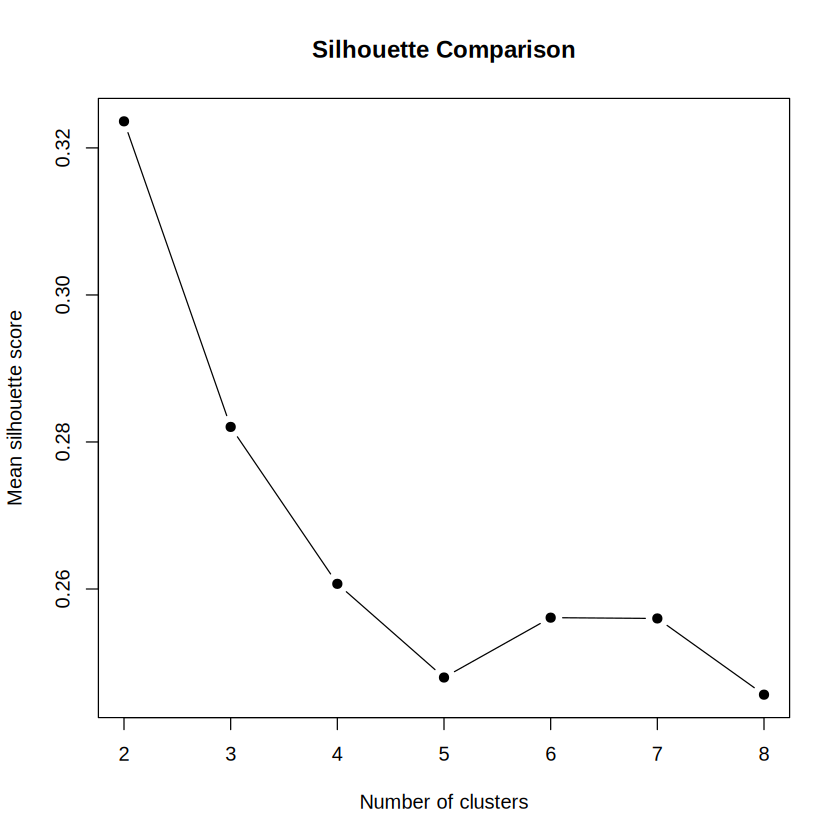

In [ ]:
ks <- 2:8
wcss <- sapply(ks, function(k) kmeans(X, centers = k, nstart = 15, iter.max = 100)$tot.withinss)
plot(ks, wcss, type = "b", pch = 19, xlab = "Number of clusters", ylab = "Within-cluster sum of squares", main = "Elbow Method")
sub_idx <- sample(seq_len(nrow(X)), min(900, nrow(X)))
sil_scores <- sapply(ks, function(k) {
 fit <- kmeans(X[sub_idx, , drop = FALSE], centers = k, nstart = 10)
 mean(cluster::silhouette(fit$cluster, dist(X[sub_idx, , drop = FALSE]))[, 3])
})
plot(ks, sil_scores, type = "b", pch = 19, xlab = "Number of clusters", ylab = "Mean silhouette score", main = "Silhouette Comparison")
best_k <- ks[which.max(sil_scores)]
cat("Selected k:", best_k, "\n")

## 4. K-Means, hierarchical clustering, PCA

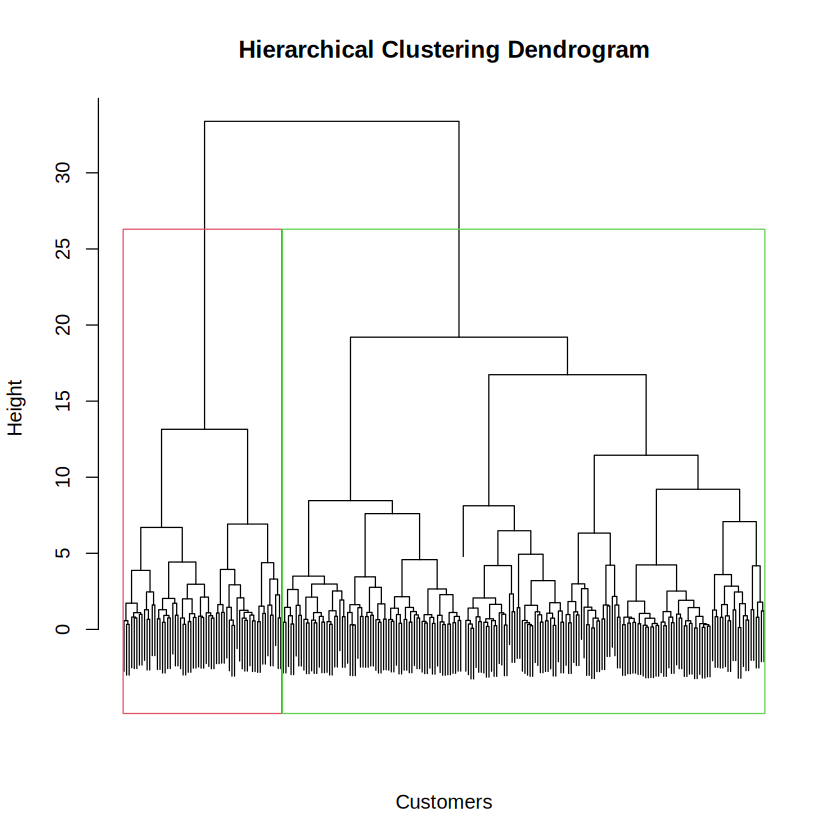

PCA variance explained: 74 %


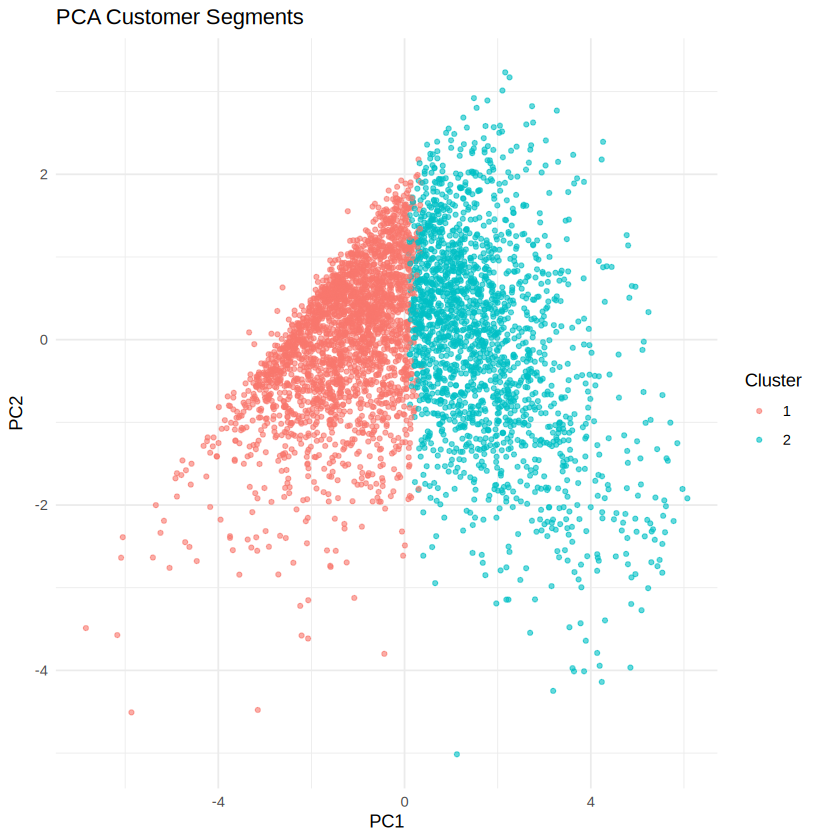

In [ ]:
km <- kmeans(X, centers = best_k, nstart = 30)
customers$Cluster <- factor(km$cluster)
hc_idx <- sample(seq_len(nrow(X)), min(250, nrow(X)))
hc <- hclust(dist(X[hc_idx, , drop = FALSE]), method = "ward.D2")
plot(hc, labels = FALSE, main = "Hierarchical Clustering Dendrogram", xlab = "Customers", sub = "")
rect.hclust(hc, k = best_k, border = 2:6)
pca <- prcomp(X, center = FALSE, scale. = FALSE)
customers$PC1 <- pca$x[, 1]
customers$PC2 <- pca$x[, 2]
ggplot(customers, aes(PC1, PC2, color = Cluster)) + geom_point(alpha = .6, size = 1.1) + theme_minimal() + ggtitle("PCA Customer Segments")
cat("PCA variance explained:", round(sum(summary(pca)$importance[2, 1:2]) * 100, 1), "%\n")

## 5. Cluster profiling and high-value group

In [ ]:
profile <- customers |> group_by(Cluster) |>
 summarise(Count = n(), across(all_of(features), median), .groups = "drop")
print(profile)
high_value_cluster <- as.character(profile$Cluster[which.max(profile$Monetary)])
customers$HighValue <- factor(ifelse(customers$Cluster == high_value_cluster, "Yes", "No"), levels = c("No", "Yes"))
cat("High value segment:", high_value_cluster, "\n")

# A tibble: 2 × 8
  Cluster Count Recency Frequency Monetary AvgTransaction Quantity
  <fct>   <int>   <dbl>     <dbl>    <dbl>          <dbl>    <dbl>
1 1        2473    95.9         1     336.           214.      185
2 2        1865    21.9         5    1927.           381.     1160
# ℹ 1 more variable: PurchaseFrequency <dbl>
High value segment: 2 


## 6. Random Forest and SVM prediction

In [ ]:
set.seed(42)
idx_yes <- which(customers$HighValue == "Yes")
idx_no <- which(customers$HighValue == "No")
train_idx <- c(sample(idx_yes, floor(.8 * length(idx_yes))), sample(idx_no, floor(.8 * length(idx_no))))
train <- customers[train_idx, c(features, "HighValue")]
test <- customers[-train_idx, c(features, "HighValue")]
rf <- randomForest::randomForest(HighValue ~ ., data = train, ntree = 150, importance = TRUE)
svm <- e1071::svm(HighValue ~ ., data = train, kernel = "radial", scale = TRUE, probability = TRUE)
rf_prob <- predict(rf, test, type = "prob")[, "Yes"]
svm_prediction <- predict(svm, test, probability = TRUE)
svm_prob <- attr(svm_prediction, "probabilities")[, "Yes"]

## 7. Model evaluation

             Accuracy Precision Recall    F1   AUC
RandomForest    0.987     0.981  0.989 0.985 1.000
SVM             0.986     0.981  0.987 0.984 0.999
      Predicted
Actual  No Yes
   No  488   7
   Yes   4 369
      Predicted
Actual  No Yes
   No  488   7
   Yes   5 368


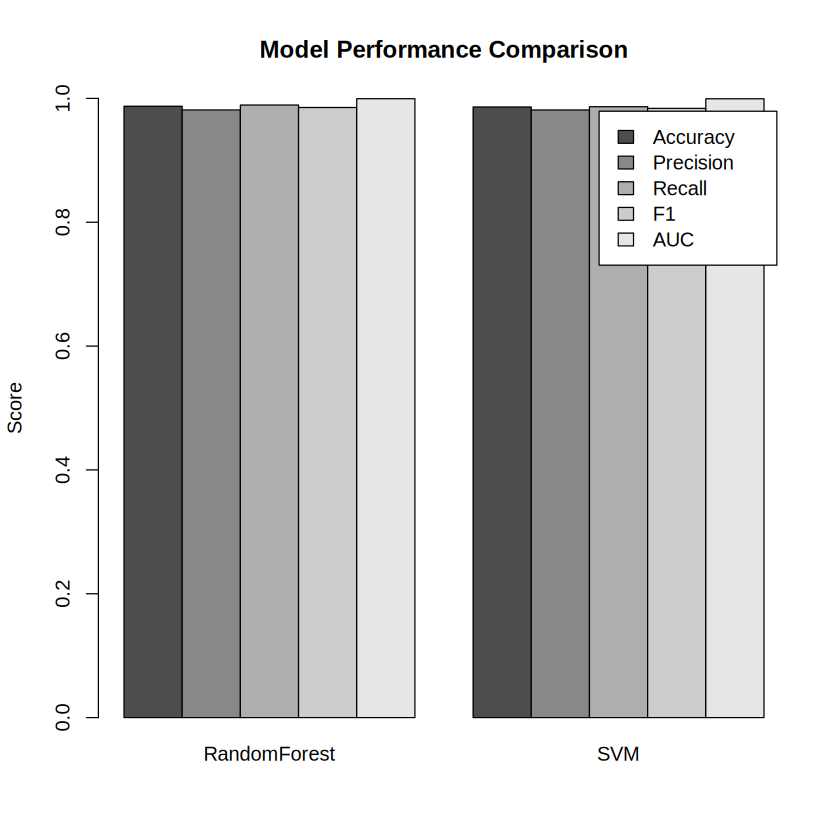

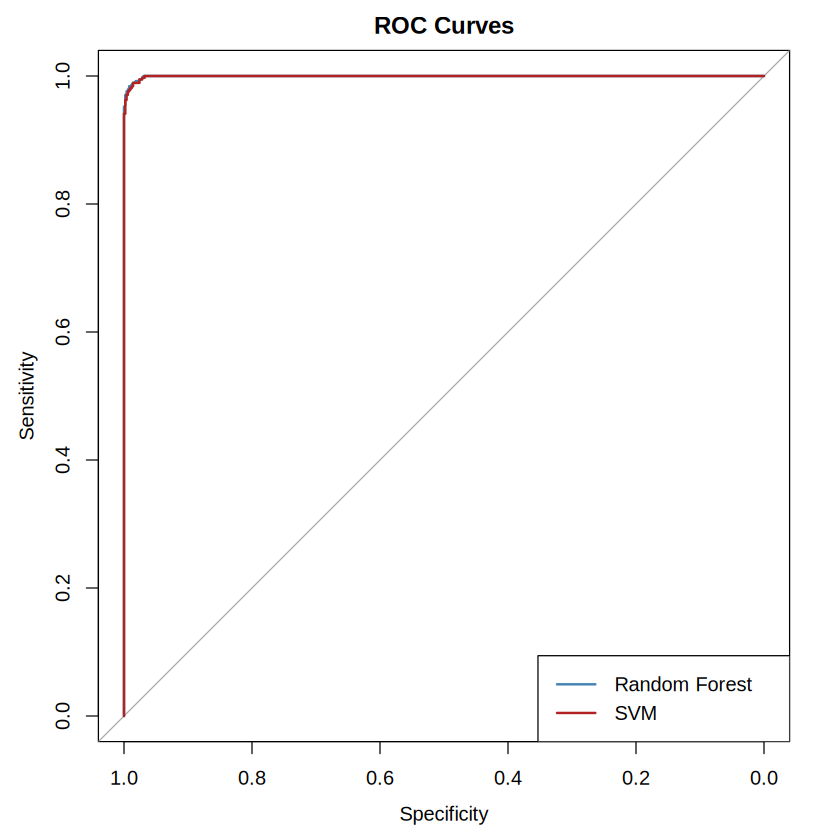

In [ ]:
evaluate <- function(probs, truth) {
 pred <- factor(ifelse(probs >= 0.5, "Yes", "No"), levels = c("No", "Yes"))
 cm <- table(Actual = truth, Predicted = pred)
 tp <- cm["Yes", "Yes"]; fp <- cm["No", "Yes"]
 fn <- cm["Yes", "No"]; tn <- cm["No", "No"]
 precision <- tp / max(1, tp + fp)
 recall <- tp / max(1, tp + fn)
 metrics <- c(Accuracy = (tp + tn) / sum(cm), Precision = precision, Recall = recall,
              F1 = 2 * precision * recall / max(1e-10, precision + recall),
              AUC = as.numeric(pROC::auc(pROC::roc(truth, probs, levels = c("No", "Yes"), quiet = TRUE))))
 list(metrics = metrics, cm = cm)
}
a <- evaluate(rf_prob, test$HighValue)
b <- evaluate(svm_prob, test$HighValue)
results <- rbind(RandomForest = a$metrics, SVM = b$metrics)
print(round(results, 3))
print(a$cm)
print(b$cm)
barplot(t(results), beside = TRUE, legend.text = TRUE, ylim = c(0, 1), main = "Model Performance Comparison", ylab = "Score")
roc_rf <- pROC::roc(test$HighValue, rf_prob, quiet = TRUE)
roc_svm <- pROC::roc(test$HighValue, svm_prob, quiet = TRUE)
plot(roc_rf, col = "steelblue", main = "ROC Curves")
plot(roc_svm, add = TRUE, col = "firebrick")
legend("bottomright", legend = c("Random Forest", "SVM"), col = c("steelblue", "firebrick"), lwd = 2)

## 8. Feature importance and 3D visualization

HTML widgets cannot be represented in plain text (need html)

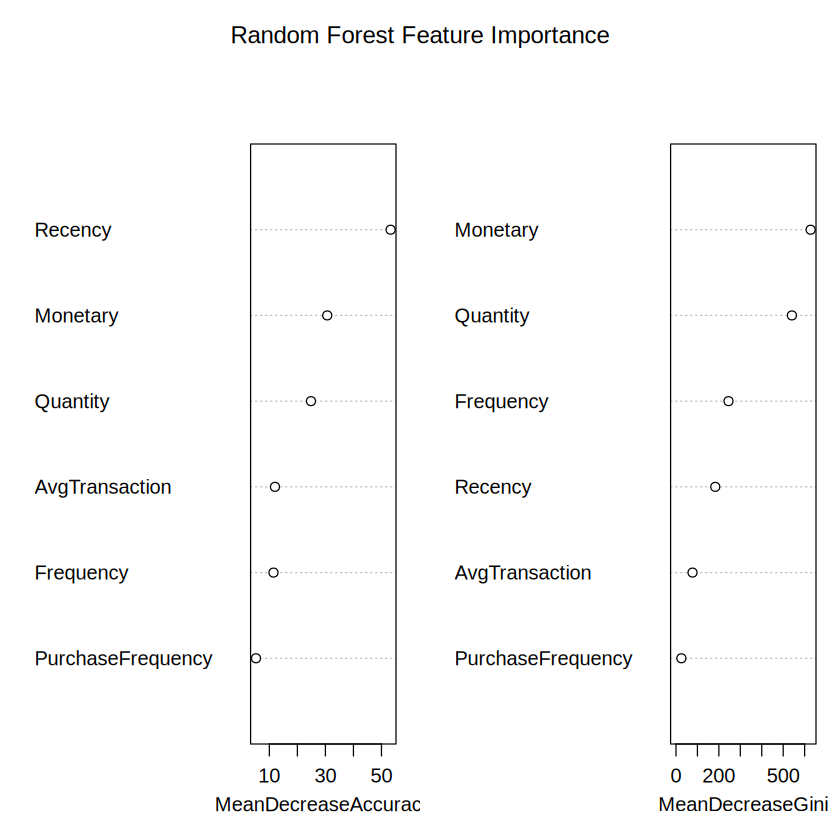

In [ ]:
randomForest::varImpPlot(rf, main = "Random Forest Feature Importance")
pca3 <- prcomp(X, center = FALSE, scale. = FALSE)$x[, 1:3]
fig <- plotly::plot_ly(x = pca3[, 1], y = pca3[, 2], z = pca3[, 3],
                     color = customers$Cluster, type = "scatter3d", mode = "markers",
                     marker = list(size = 2))
fig

## 9. Marketing recommendations

- **High-value segment:** Loyalty rewards, early access, and personalised product recommendations.
- **Frequent lower-spend customers:** Bundles, cross-selling, and basket-size incentives.
- **Infrequent or inactive customers:** Targeted reactivation offers and retention messages.
- **New or occasional customers:** Welcome campaigns and product education.

## Conclusion
RFM-based customer clustering identifies meaningful differences in purchasing behaviour. K-Means and hierarchical clustering provide complementary segment views, while PCA supports visual interpretation. Random Forest and SVM can classify membership in the selected high-value cluster; their metrics should be interpreted as predictions of a cluster-derived label rather than independent proof of future customer value.